## Dependencias

In [ ]:
%%capture
!pip install giotto-tda

In [ ]:
import pandas as pd
import numpy as np
#import gudhi as gd
from pylab import *
from sklearn.decomposition import PCA
from gtda.plotting import plot_point_cloud
from gtda.time_series import SingleTakensEmbedding
import scipy as sp
from math import floor,ceil
from sklearn.preprocessing import StandardScaler
import warnings
from ipywidgets import interact, interactive, fixed, interact_manual,IntSlider
import ipywidgets as widgets
import xarray as xr
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as clrs
import seaborn as sns
import plotly.graph_objects as go
from gtda.homology import VietorisRipsPersistence
from gtda.plotting import plot_diagram

%matplotlib inline


In [ ]:
def moving_average(a: np.ndarray, n: int) :
  """Calcula el promedio movil a n dias de la señal a"""
  ret = np.cumsum(a, dtype=float)
  ret[n:] = ret[n:] - ret[:-n]
  return ret[n - 1:] / n

In [ ]:
SR21 = xr.open_mfdataset('dlwrf.sfc.gauss.2021.nc')
SR20 = xr.open_mfdataset('dlwrf.sfc.gauss.2020.nc')
SR19 = xr.open_mfdataset('dlwrf.sfc.gauss.2019.nc')
SR18 = xr.open_mfdataset('dlwrf.sfc.gauss.2018.nc')
SR17 = xr.open_mfdataset('dlwrf.sfc.gauss.2017.nc')

In [ ]:
SR17.dlwrf

<xarray.DataArray 'dlwrf' (time: 365, lat: 94, lon: 192)>
dask.array<open_dataset-f75d726078363df8f20f304afe6a4324dlwrf, shape=(365, 94, 192), dtype=float32, chunksize=(365, 94, 192), chunktype=numpy.ndarray>
Coordinates:
  * lat      (lat) float32 88.54 86.65 84.75 82.85 ... -84.75 -86.65 -88.54
  * lon      (lon) float32 0.0 1.875 3.75 5.625 7.5 ... 352.5 354.4 356.2 358.1
  * time     (time) datetime64[ns] 2017-01-01 2017-01-02 ... 2017-12-31
Attributes:
    long_name:      daily mean 6-Hourly Mean of Downward Longwave Radiation F...
    units:          W/m^2
    precision:      1
    GRIB_id:        205
    GRIB_name:      DLWRF
    var_desc:       Downward Longwave Radiation Flux
    dataset:        NCEP/DOE AMIP-II Reanalysis (Reanalysis-2) Daily Averages
    level_desc:     Surface
    statistic:      Mean
    parent_stat:    Individual Obs
    standard_name:  surface_downward_longwave_radiation_flux
    cell_methods:   time: mean
    actual_range:   [ 31.399902 513.19995 ]
    valid_range:    [-135.  635.]

In [ ]:
def fit_embedder(embedder: SingleTakensEmbedding, y: np.ndarray, verbose: bool=True) -> np.ndarray:
    """Fits a Takens embedder and displays optimal search parameters."""
    y_embedded = embedder.fit_transform(y)
    if verbose:
        print(f"Shape of embedded time series: {y_embedded.shape}")
        print(
            f"Optimal embedding dimension is {embedder.dimension_} and time delay is {embedder.time_delay_}"
        )
    return embedder.dimension,embedder.time_delay_,y_embedded

In [ ]:
def tank(x:np.ndarray,embedder: SingleTakensEmbedding,PC: int=2,verbose=True) -> list:
  '''Usando un encajador dado, obtiene los primeros n
  componentes principales de cada encaje de la variable de entrada'''
  pca = PCA(n_components=PC)
  _,_,precipitacion_embedded = fit_embedder(embedder,x,False)
  precs2d=pca.fit_transform(precipitacion_embedded)
  pca.fit_transform(precipitacion_embedded)

  # Grafica de varianza explicada
  if verbose:
    plt.figure()
    plt.bar(
        range(1,len(pca.explained_variance_ratio_)+1),
        pca.explained_variance_ratio_*100
        )
    plt.xticks([1,2])
    plt.title('% de varianza explicada por componente principal')


  return precs2d

## Funciones auxiliares

In [ ]:
#from sklearn.preprocessing import StandardScaler
#print(scaler.fit(data))

def selector(lat: int,lon: int):
  '''Obtiene la serie de tiempo del indice de latitud y longitud especificados'''
  ## Se hace para no arruinar la biyeccion
  SR=np.concatenate([
      SR17.dlwrf.isel(lat=lat,lon=lon),
      SR18.dlwrf.isel(lat=lat,lon=lon),
      SR19.dlwrf.isel(lat=lat,lon=lon),
      SR20.dlwrf.isel(lat=lat,lon=lon),
      SR21.dlwrf.isel(lat=lat,lon=lon),
      ])
  scaler = StandardScaler()
  #SR=SR.reshape(-1, 1)
  #scaler.fit(SR)
  #return (scaler.transform(SR))
  return SR


In [ ]:
def selector_by_value(lat: float,lon: float):
  '''Obtiene la serie de tiempo de la latitud y longitud especificados'''
  ## Se hace para no arruinar la biyeccion
  scaler = StandardScaler()
  lat_i=int(np.where(SR17.dlwrf.lat == lat)[0][0])
  lon_i=int(np.where(SR17.dlwrf.lon == lon)[0][0])
  SR=np.concatenate([
      SR17.dlwrf.isel(lat=lat_i,lon=lon_i),
      SR18.dlwrf.isel(lat=lat_i,lon=lon_i),
      SR19.dlwrf.isel(lat=lat_i,lon=lon_i),
      SR20.dlwrf.isel(lat=lat_i,lon=lon_i),
      SR21.dlwrf.isel(lat=lat_i,lon=lon_i),
      ])
  #SR=SR.reshape(-1, 1)
  #scaler.fit(SR)
  #return (scaler.transform(SR))
  return SR

In [ ]:
def embeddingPipelineManual(Dimension: int,Retraso_Temporal: int,Suavizado: int,
                            Zancada: int,signal: np.ndarray,PC: int=3,
                            verbose: bool=True):
  '''Pipeline que crea un embedder con parametros dados para los encajes'''
  if verbose:
    print("Tamaño de ventana:",(Dimension-1)*Retraso_Temporal)
  embedder_generic = SingleTakensEmbedding(
      parameters_type="fixed",
      time_delay=Retraso_Temporal,
      dimension=Dimension,
      stride=Zancada,
  )
  signalMA=moving_average(signal,Suavizado)
  signalembedded=tank(signalMA,embedder_generic,PC,verbose)
  return signalembedded

| Planta           |Latitud,Longitud  | Factor de planta  |
|----------------------|------------|----------|
| Benban               | 24º, 32º   | FP: 26%  |
| Solar Star I, II     | 34º, 242º  | FP: 25%  |
| Sunlight Solar       | 33º, 245º  | FP: 27%  |
| Topaz Solar Farm     | 35º, 240º  | FP: 26%  |
| Mount Signal Solar   | 32º, 245º  | FP: 17%  |
| Mesquite Solar       | 33º, 248º  | FP: 35%  |
| McCoy Solar          | 33º, 246º  | FP: 34%  |
| Agua Caliente        | 32º, 247º  | FP: 21%  |
| Springbok Solar      | 35º, 243º  | FP: 19%  |
| Silver State         | 35º, 245º  | FP: 33%  |
| California Valley    | 35º, 241º  | FP: 31%  |
| Stateline Solar      | 35º, 245º  | FP: 30%  |
| Moapa Paiute         | 36º, 246º  | FP: 29%  |
| Westlands Solar Park | 36º, 241º  | FP: 29%  |
| Garland Solar        | 34º, 242º  | FP: 23%  |
| Tranquility Solar    | 36º, 240º  | FP: 20%  |
| Cestas Solar Park    | 44º, 0º    | FP: 13%  |

In [ ]:
Benban=selector_by_value(23.8092,31.875)
Solar_star=selector_by_value(33.3328,61.875)
Sunlight_solar=selector_by_value(33.3328,245.625)
Topaz=selector_by_value(35.2375,240)
Mount=selector_by_value(31.4281,245.625)
Mezquite=selector_by_value(33.3328,247.5)
McCoy=selector_by_value(33.3328,292.5)
AguaCaliente=selector_by_value(31.4281,247.5)
Springbook=selector_by_value(35.2375,243.75)
SilverState=selector_by_value(35.2375,245.625)
CaliforniaValley=selector_by_value(35.2375,241.875)
## Hay 2 ubicadas en el mismo lugar, se toma el nombre de la mas eficiente
#StatelineSolar=selector_by_value(35.2375,245.625)
## Hay 3 ubicadas en el mismo lugar, se toma el nombre de la mas eficiente
#Moapa=selector_by_value(35.2375,245.625)
Westlands=selector_by_value(35.2375,241.875)
Garland=selector_by_value(33.3328,241.875)
Tranquility=selector_by_value(35.2375,240)
Cestas=selector_by_value(44.7611,0)




In [ ]:
plantas=(Benban,Solar_star,Sunlight_solar,Topaz,Mount,Mezquite,McCoy,
AguaCaliente,Springbook,SilverState,CaliforniaValley,Westlands,Garland,
Tranquility,Cestas)


### Parametros

In [ ]:
dim,delay,ma,stride=37,10,14,1
#dim,delay,ma,stride=19,10,14,1
#dim,delay,ma,stride=11,3,14,1
#dim,delay,ma,stride=31,6,14,1
#dim,delay,ma,stride=37,10,14,1


In [ ]:
encajesPlantas=[]
for i in plantas:
  encajesPlantas.append(embeddingPipelineManual(dim,delay,ma,stride,i,2,False))

## Definición del descriptor

Trabajo futuro: no usar solo el descriptor. Tomar la diferencia entre este y la nube de puntos y hacer algun tipo de diferencia


In [ ]:
def circle(point_cloud: np.ndarray) -> np.ndarray:
  '''Recibe una nube de puntos, ajusta el circulo teorico centrado en cero
  que deberia trazar y devuelve su radio'''
  X,Y=point_cloud[:,0],point_cloud[:,1]
  X2,Y2=np.square(X),np.square(Y)
  R=1/point_cloud.shape[0]*sum(sqrt((X2+Y2)))
  return R


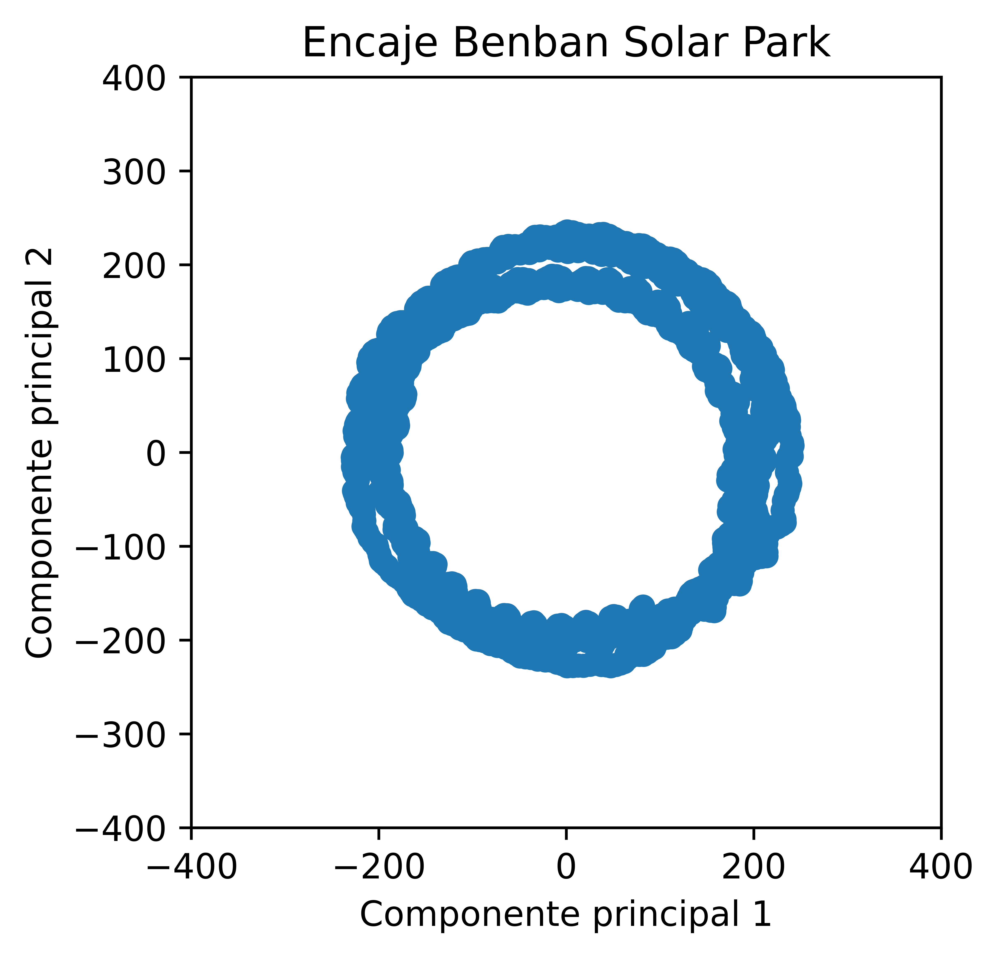

In [ ]:
plt.figure(dpi=1200)

plt.scatter(encajesPlantas[0][:,0],encajesPlantas[0][:,1])
ax = plt.gca() #you first need to get the axis handle
ax.set_aspect('equal')
ax.set_title('Encaje Benban Solar Park')
ax.set_xlabel('Componente principal 1')
ax.set_ylabel('Componente principal 2')
ax.set_xlim((-400,400))
ax.set_ylim((-400,400))
plt.show()


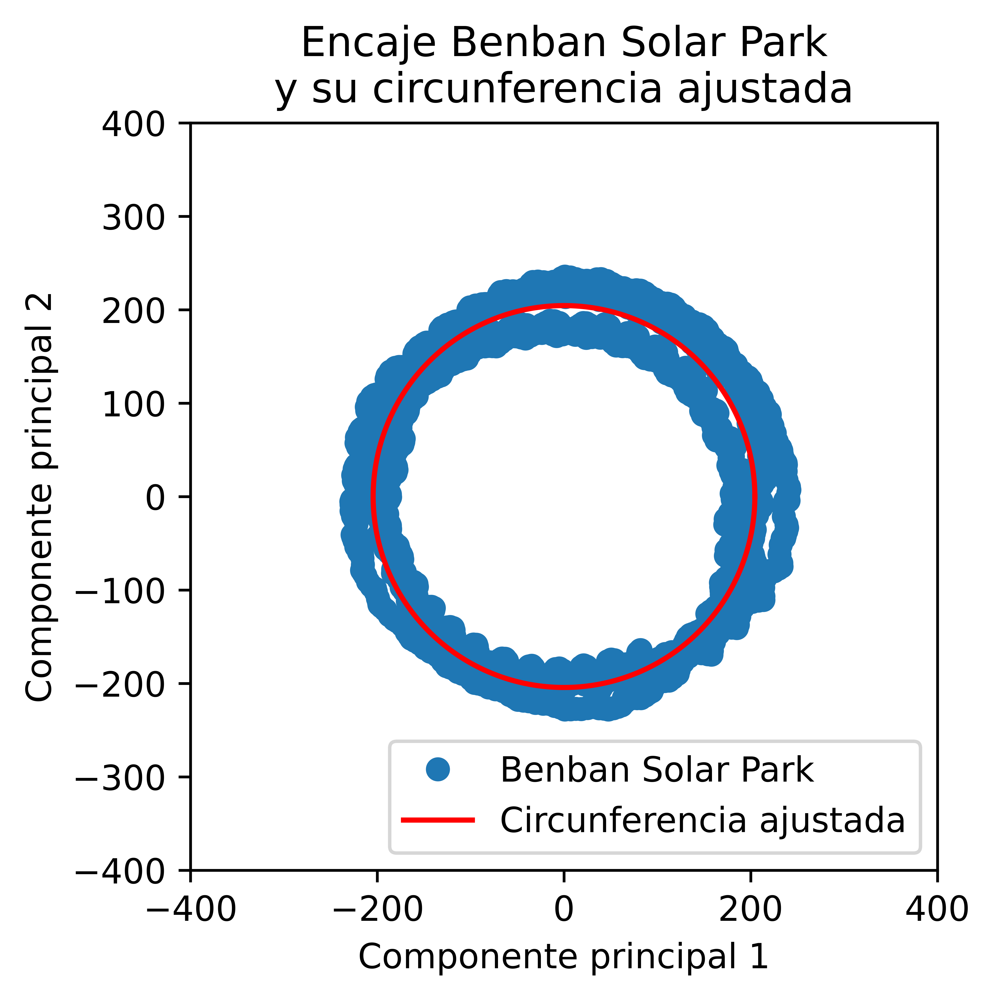

In [ ]:
r=circle(encajesPlantas[0])
plt.figure(dpi=1200)

theta=np.linspace(0,2*np.pi,1000)
x=r*np.cos(theta)
y=r*np.sin(theta)
plt.plot(encajesPlantas[0][:,0],encajesPlantas[0][:,1],'o',label='Benban Solar Park')
plt.plot(x,y,'r',label='Circunferencia ajustada')

ax = plt.gca() #you first need to get the axis handle
ax.set_aspect('equal')
ax.set_title('Encaje Benban Solar Park\ny su circunferencia ajustada')
ax.set_xlabel('Componente principal 1')
ax.set_ylabel('Componente principal 2')
plt.legend(loc='lower right')
ax.set_xlim((-400,400))
ax.set_ylim((-400,400))

plt.show()


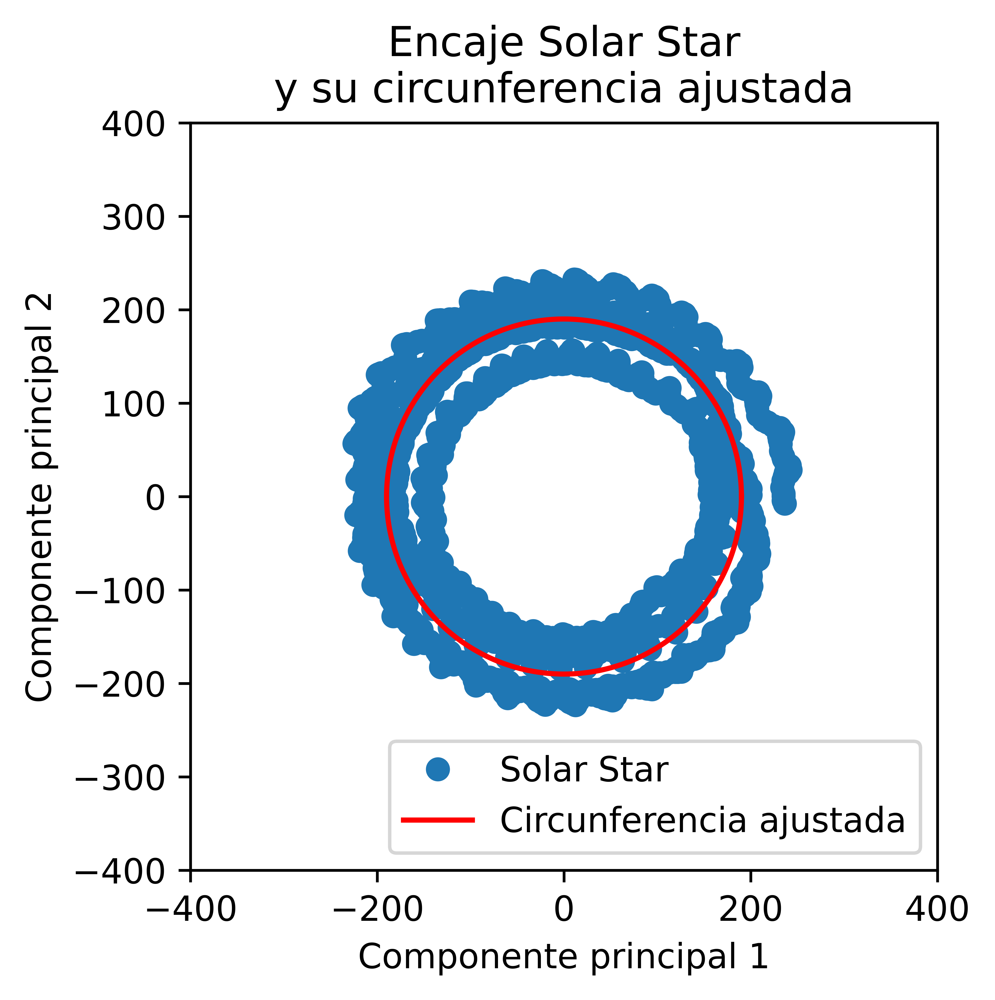

In [ ]:
r=circle(encajesPlantas[1])
plt.figure(dpi=1200)

theta=np.linspace(0,2*np.pi,1000)
x=r*np.cos(theta)
y=r*np.sin(theta)
plt.plot(encajesPlantas[1][:,0],encajesPlantas[1][:,1],'o',label='Solar Star')
plt.plot(x,y,'r',label='Circunferencia ajustada')

ax = plt.gca() #you first need to get the axis handle
ax.set_aspect('equal')
ax.set_title('Encaje Solar Star\ny su circunferencia ajustada')
ax.set_xlabel('Componente principal 1')
ax.set_ylabel('Componente principal 2')
plt.legend(loc='lower right')
ax.set_xlim((-400,400))
ax.set_ylim((-400,400))

plt.show()


In [ ]:
radiosPlantas=[]
for i in encajesPlantas:
  tmp=circle(i)
  radiosPlantas.append(tmp)
  print(tmp)

204.38782565738978
190.02307293002747
228.80554482744836
106.6287155508267
215.6470703517772
251.99309983817528
119.65668274092894
259.5193364976687
211.40970280076144
237.1951788503904
161.58167512999736
161.58167512999736
83.48115069267766
106.62871555082766
167.6900615238239


In [ ]:
mediasPlantas=[]
for i in plantas:
  tmp=np.mean(i)
  mediasPlantas.append(tmp)
  print(tmp)

340.3758
294.94434
310.10632
302.2117
326.18964
305.07956
382.27643
323.25244
291.62708
289.2571
295.273
295.273
310.69394
302.2117
309.17908


## Estados unidos

In [ ]:
lat_i,lon_i=np.where(SR21.lat==50.4752)[0][0],np.where(SR21.lon==238.125)[0][0]
lat_f,lon_f=np.where(SR21.lat==31.4281)[0][0],np.where(SR21.lon==277.5)[0][0]

X=np.zeros((lat_f-lat_i,lon_f-lon_i,2))

for i in range(X.shape[0]):
  for j in range(X.shape[1]):
    tmp=selector(i+lat_i,j+lon_i)
    tmp_embedded=embeddingPipelineManual(dim,delay,ma,stride,tmp,2,False)
    tmp_r=circle(tmp_embedded)
    X[i][j][0]=np.mean(tmp)
    X[i][j][1]=tmp_r

### Draft pareto

<Figure size 7200x4800 with 0 Axes>

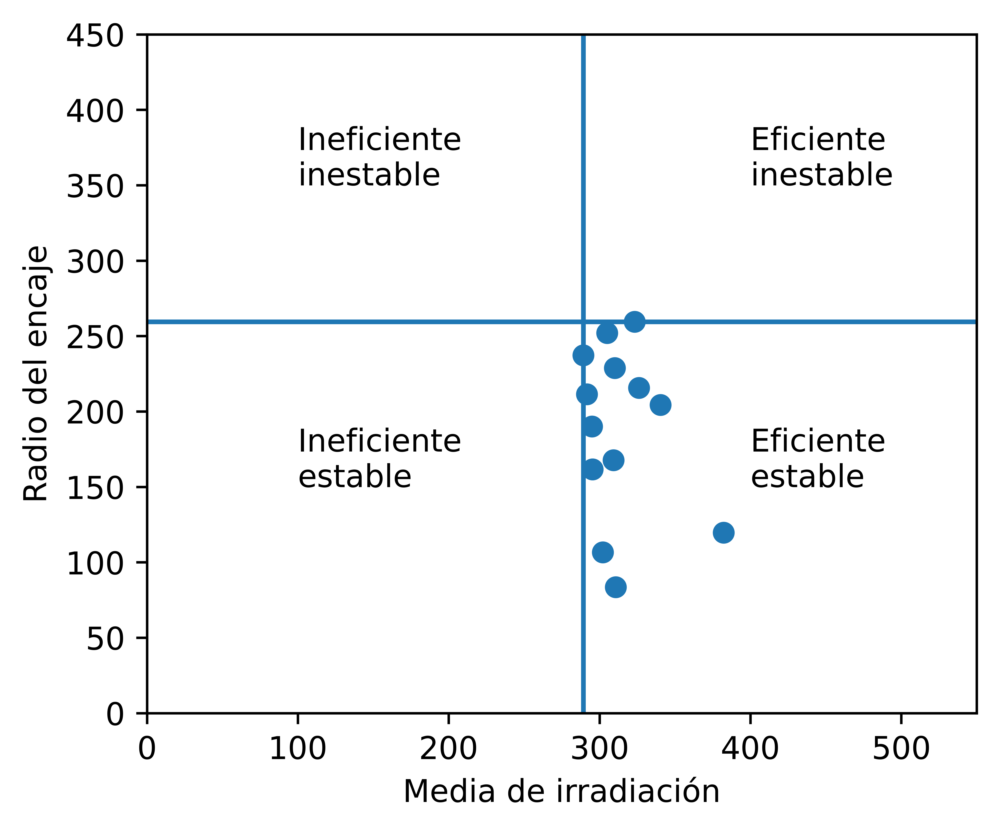

In [ ]:
plt.figure(dpi=1200)
plt.figure(dpi=1200)

plt.scatter(mediasPlantas,radiosPlantas)
plt.axvline(x=min(mediasPlantas))
plt.axhline(y=max(radiosPlantas))
plt.xlabel('Media de irradiación')
plt.ylabel('Radio del encaje')


## Lineas
plt.annotate('Eficiente\nestable',(400,150))
plt.annotate('Eficiente \ninestable',(400,350))
plt.annotate('Ineficiente\nestable',(100,150))
plt.annotate('Ineficiente\ninestable',(100,350))





plt.xlim((0,550))
plt.ylim((0,450))


ax = plt.gca() #you first need to get the axis handle
ax.set_aspect('equal')

plt.show()

## Estados unidos completo

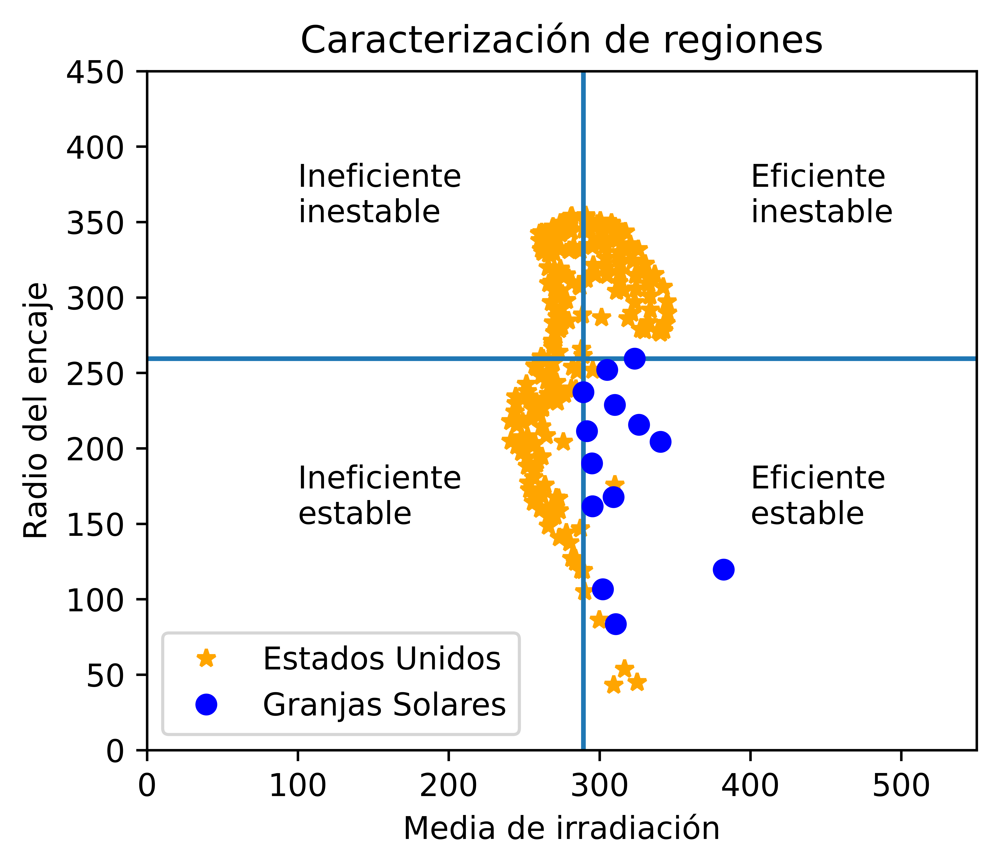

In [ ]:

plt.figure(dpi=1200)

## Lineas
plt.annotate('Eficiente\nestable',(400,150))
plt.annotate('Eficiente \ninestable',(400,350))
plt.annotate('Ineficiente\nestable',(100,150))
plt.annotate('Ineficiente\ninestable',(100,350))










# Todo USA
for i in range(X.shape[0]):
  for j in range(X.shape[1]):
    plt.plot(X[i][j][0],X[i][j][1],'*',color='orange')
plt.plot(X[-1][-1][0],X[-1][-1][1],'*',color='orange',label='Estados Unidos')

## Plantas
plt.axvline(x=min(mediasPlantas))
plt.axhline(y=max(radiosPlantas))
plt.plot(mediasPlantas,radiosPlantas,'o',color='blue',label='Granjas Solares')



plt.xlim((0,550))
plt.ylim((0,450))

plt.xlabel('Media de irradiación')
plt.ylabel('Radio del encaje')

plt.title('Caracterización de regiones')
ax = plt.gca() #you first need to get the axis handle
ax.set_aspect('equal')
plt.legend(loc='lower left')

plt.show()

## Estados unidos norte

In [ ]:
lat_i,lon_i=np.where(SR21.lat==50.4752)[0][0],np.where(SR21.lon==238.125)[0][0]
lat_f,lon_f=np.where(SR21.lat==40.9517)[0][0],np.where(SR21.lon==277.5)[0][0]

US_north=np.zeros((lat_f-lat_i,lon_f-lon_i,2))

for i in range(US_north.shape[0]):
  for j in range(US_north.shape[1]):
    tmp=selector(i+lat_i,j+lon_i)
    tmp_embedded=embeddingPipelineManual(dim,delay,ma,stride,tmp,2,False)
    tmp_r=circle(tmp_embedded)
    US_north[i][j][0]=np.mean(tmp)
    US_north[i][j][1]=tmp_r

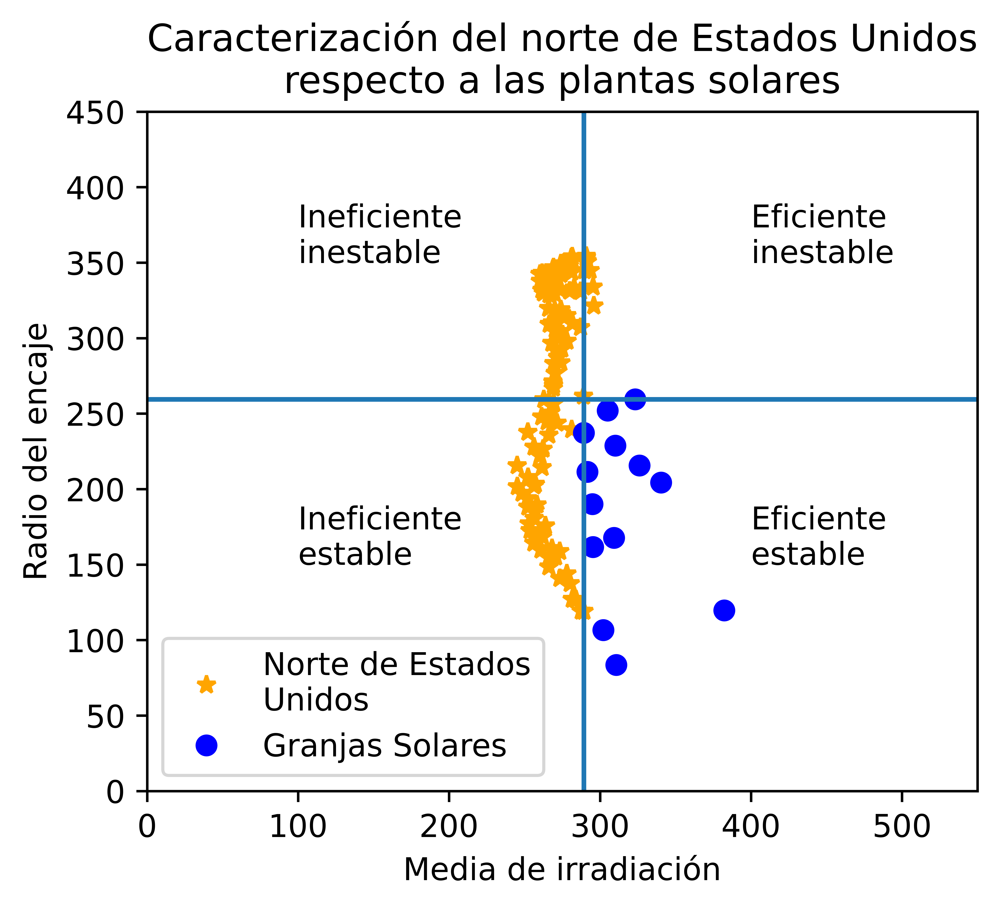

In [ ]:
plt.figure(dpi=1200)


## Lineas
plt.annotate('Eficiente\nestable',(400,150))
plt.annotate('Eficiente \ninestable',(400,350))
plt.annotate('Ineficiente\nestable',(100,150))
plt.annotate('Ineficiente\ninestable',(100,350))







# USA norte
for i in range(US_north.shape[0]):
  for j in range(US_north.shape[1]):
    plt.plot(US_north[i][j][0],US_north[i][j][1],'*',color='orange')
plt.plot(US_north[-1][-1][0],US_north[-1][-1][1],'*',color='orange',
         label='Norte de Estados\nUnidos')


## Plantas
plt.plot(mediasPlantas,radiosPlantas,'o',color='blue',label='Granjas Solares')
plt.axvline(x=min(mediasPlantas))
plt.axhline(y=max(radiosPlantas))


plt.xlabel('Media de irradiación')
plt.ylabel('Radio del encaje')
plt.legend(loc='lower left')
plt.title('Caracterización del norte de Estados Unidos\nrespecto a las plantas solares')



plt.xlim((0,550))
plt.ylim((0,450))


ax = plt.gca() #you first need to get the axis handle
ax.set_aspect('equal')
plt.show()

## Estados unidos sur

In [ ]:
lat_i,lon_i=np.where(SR21.lat==40.9517)[0][0],np.where(SR21.lon==238.125)[0][0]
lat_f,lon_f=np.where(SR21.lat==31.4281)[0][0],np.where(SR21.lon==277.5)[0][0]


US_south=np.zeros((lat_f-lat_i,lon_f-lon_i,2))

for i in range(US_south.shape[0]):
  for j in range(US_south.shape[1]):
    tmp=selector(i+lat_i,j+lon_i)
    tmp_embedded=embeddingPipelineManual(dim,delay,ma,stride,tmp,2,False)
    tmp_r=circle(tmp_embedded)
    US_south[i][j][0]=np.mean(tmp)
    US_south[i][j][1]=tmp_r

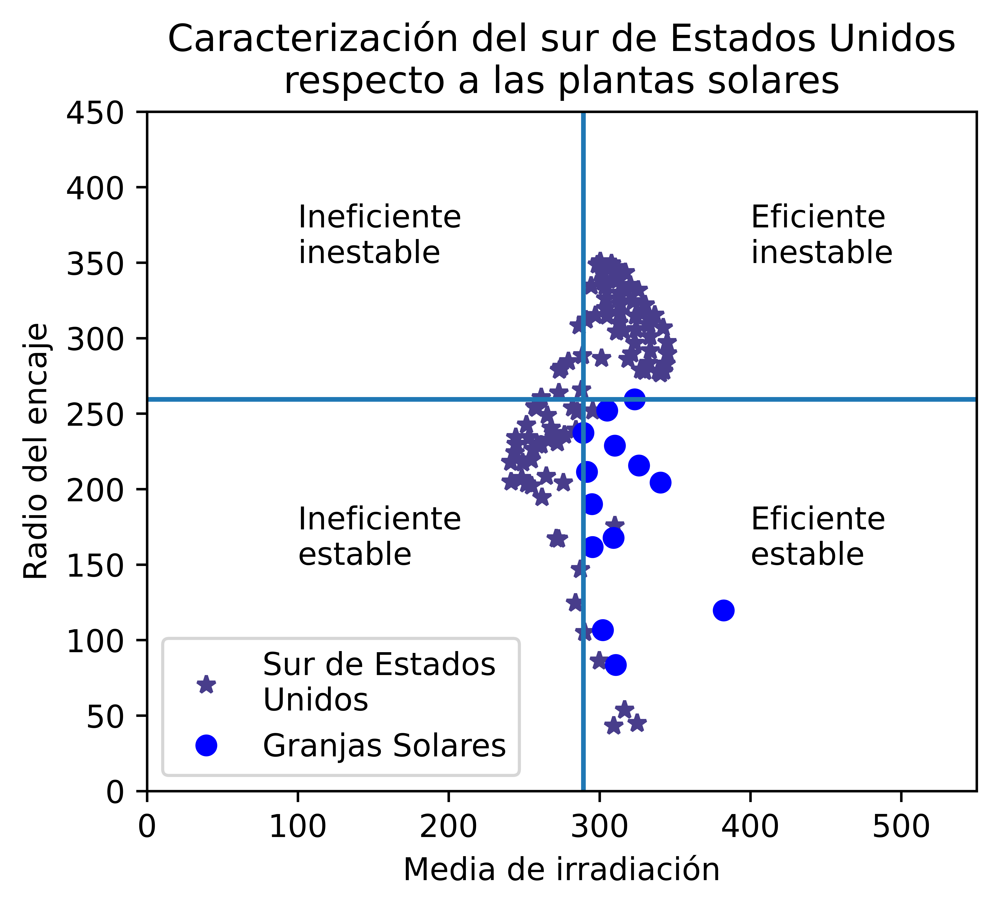

In [ ]:

plt.figure(dpi=1200)






# USA sur
for i in range(US_south.shape[0]):
  for j in range(US_south.shape[1]):
    plt.plot(US_south[i][j][0],US_south[i][j][1],'*',color='darkslateblue')
plt.plot(US_south[-1][-1][0],US_south[-1][-1][1],'*',color='darkslateblue',
         label='Sur de Estados\nUnidos')


## Plantas
plt.plot(mediasPlantas,radiosPlantas,'o',color='blue',label='Granjas Solares')
## Lineas

plt.axvline(x=min(mediasPlantas))
plt.axhline(y=max(radiosPlantas))

plt.annotate('Eficiente\nestable',(400,150))
plt.annotate('Eficiente \ninestable',(400,350))
plt.annotate('Ineficiente\nestable',(100,150))
plt.annotate('Ineficiente\ninestable',(100,350))





plt.xlabel('Media de irradiación')
plt.ylabel('Radio del encaje')
plt.legend(loc='lower left')
plt.title('Caracterización del sur de Estados Unidos\nrespecto a las plantas solares')

plt.xlim((0,550))
plt.ylim((0,450))


ax = plt.gca() #you first need to get the axis handle
ax.set_aspect('equal')
plt.show()

In [ ]:
SR21.lat

<xarray.DataArray 'lat' (lat: 94)>
array([ 88.542   ,  86.6531  ,  84.7532  ,  82.8508  ,  80.9473  ,  79.0435  ,
        77.1394  ,  75.2351  ,  73.3307  ,  71.4262  ,  69.5217  ,  67.6171  ,
        65.7125  ,  63.8079  ,  61.9033  ,  59.9986  ,  58.0939  ,  56.1893  ,
        54.2846  ,  52.3799  ,  50.4752  ,  48.5705  ,  46.6658  ,  44.7611  ,
        42.8564  ,  40.9517  ,  39.047   ,  37.1422  ,  35.2375  ,  33.3328  ,
        31.4281  ,  29.5234  ,  27.6186  ,  25.7139  ,  23.8092  ,  21.9044  ,
        19.9997  ,  18.095   ,  16.1902  ,  14.2855  ,  12.3808  ,  10.47604 ,
         8.57131 ,   6.66657 ,   4.76184 ,   2.8571  ,   0.952368,  -0.952368,
        -2.8571  ,  -4.76184 ,  -6.66657 ,  -8.57131 , -10.47604 , -12.3808  ,
       -14.2855  , -16.1902  , -18.095   , -19.9997  , -21.9044  , -23.8092  ,
       -25.7139  , -27.6186  , -29.5234  , -31.4281  , -33.3328  , -35.2375  ,
       -37.1422  , -39.047   , -40.9517  , -42.8564  , -44.7611  , -46.6658  ,
       -48.5705  , -50.4752  , -52.3799  , -54.2846  , -56.1893  , -58.0939  ,
       -59.9986  , -61.9033  , -63.8079  , -65.7125  , -67.6171  , -69.5217  ,
       -71.4262  , -73.3307  , -75.2351  , -77.1394  , -79.0435  , -80.9473  ,
       -82.8508  , -84.7532  , -86.6531  , -88.542   ], dtype=float32)
Coordinates:
  * lat      (lat) float32 88.54 86.65 84.75 82.85 ... -84.75 -86.65 -88.54
Attributes:
    units:               degrees_north
    actual_range:        [ 88.542 -88.542]
    long_name:           Latitude
    standard_name:       latitude
    axis:                Y
    coordinate_defines:  point

In [ ]:
SR21.lon

<xarray.DataArray 'lon' (lon: 192)>
array([  0.   ,   1.875,   3.75 ,   5.625,   7.5  ,   9.375,  11.25 ,  13.125,
        15.   ,  16.875,  18.75 ,  20.625,  22.5  ,  24.375,  26.25 ,  28.125,
        30.   ,  31.875,  33.75 ,  35.625,  37.5  ,  39.375,  41.25 ,  43.125,
        45.   ,  46.875,  48.75 ,  50.625,  52.5  ,  54.375,  56.25 ,  58.125,
        60.   ,  61.875,  63.75 ,  65.625,  67.5  ,  69.375,  71.25 ,  73.125,
        75.   ,  76.875,  78.75 ,  80.625,  82.5  ,  84.375,  86.25 ,  88.125,
        90.   ,  91.875,  93.75 ,  95.625,  97.5  ,  99.375, 101.25 , 103.125,
       105.   , 106.875, 108.75 , 110.625, 112.5  , 114.375, 116.25 , 118.125,
       120.   , 121.875, 123.75 , 125.625, 127.5  , 129.375, 131.25 , 133.125,
       135.   , 136.875, 138.75 , 140.625, 142.5  , 144.375, 146.25 , 148.125,
       150.   , 151.875, 153.75 , 155.625, 157.5  , 159.375, 161.25 , 163.125,
       165.   , 166.875, 168.75 , 170.625, 172.5  , 174.375, 176.25 , 178.125,
       180.   , 181.875, 183.75 , 185.625, 187.5  , 189.375, 191.25 , 193.125,
       195.   , 196.875, 198.75 , 200.625, 202.5  , 204.375, 206.25 , 208.125,
       210.   , 211.875, 213.75 , 215.625, 217.5  , 219.375, 221.25 , 223.125,
       225.   , 226.875, 228.75 , 230.625, 232.5  , 234.375, 236.25 , 238.125,
       240.   , 241.875, 243.75 , 245.625, 247.5  , 249.375, 251.25 , 253.125,
       255.   , 256.875, 258.75 , 260.625, 262.5  , 264.375, 266.25 , 268.125,
       270.   , 271.875, 273.75 , 275.625, 277.5  , 279.375, 281.25 , 283.125,
       285.   , 286.875, 288.75 , 290.625, 292.5  , 294.375, 296.25 , 298.125,
       300.   , 301.875, 303.75 , 305.625, 307.5  , 309.375, 311.25 , 313.125,
       315.   , 316.875, 318.75 , 320.625, 322.5  , 324.375, 326.25 , 328.125,
       330.   , 331.875, 333.75 , 335.625, 337.5  , 339.375, 341.25 , 343.125,
       345.   , 346.875, 348.75 , 350.625, 352.5  , 354.375, 356.25 , 358.125],
      dtype=float32)
Coordinates:
  * lon      (lon) float32 0.0 1.875 3.75 5.625 7.5 ... 352.5 354.4 356.2 358.1
Attributes:
    units:               degrees_east
    long_name:           Longitude
    actual_range:        [  0.    358.125]
    standard_name:       longitude
    axis:                X
    coordinate_defines:  point

## Mexico norte

In [ ]:
lat_i,lon_i=np.where(SR21.lat==33.3328)[0][0],np.where(SR21.lon==243.75)[0][0]
lat_f,lon_f=np.where(SR21.lat==23.8092)[0][0],np.where(SR21.lon==262.5)[0][0]

mexico_Norte=np.zeros((lat_f-lat_i,lon_f-lon_i,2))

for i in range(mexico_Norte.shape[0]):
  for j in range(mexico_Norte.shape[1]):
    tmp=selector(i+lat_i,j+lon_i)
    tmp_embedded=embeddingPipelineManual(dim,delay,ma,stride,tmp,2,False)
    tmp_r=circle(tmp_embedded)
    mexico_Norte[i][j][0]=np.mean(tmp)
    mexico_Norte[i][j][1]=tmp_r

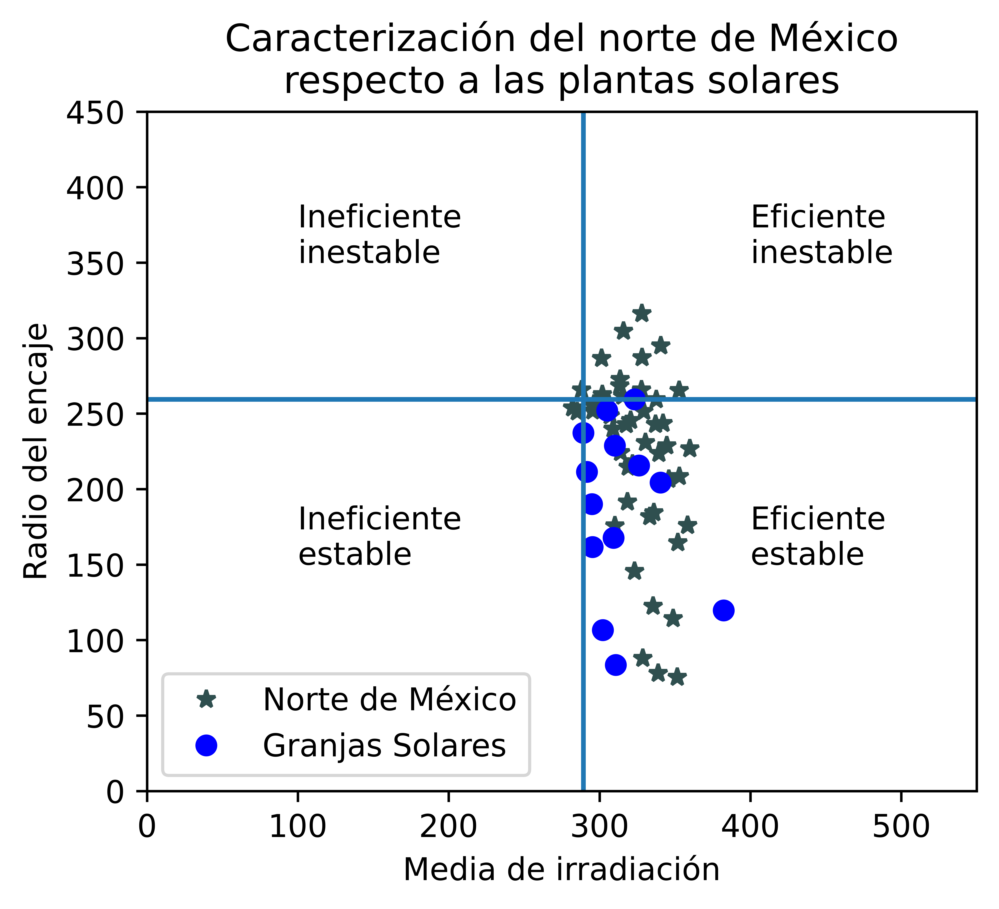

In [ ]:
plt.figure(dpi=1200)




plt.annotate('Eficiente\nestable',(400,150))
plt.annotate('Eficiente \ninestable',(400,350))
plt.annotate('Ineficiente\nestable',(100,150))
plt.annotate('Ineficiente\ninestable',(100,350))








# USA sur
for i in range(mexico_Norte.shape[0]):
  for j in range(mexico_Norte.shape[1]):
    plt.plot(mexico_Norte[i][j][0],mexico_Norte[i][j][1],'*',color='darkslategrey')
plt.plot(mexico_Norte[-1][-1][0],mexico_Norte[-1][-1][1],'*',color='darkslategrey',
         label='Norte de México')


## Plantas
plt.plot(mediasPlantas,radiosPlantas,'o',color='blue',label='Granjas Solares')
plt.axvline(x=min(mediasPlantas))
plt.axhline(y=max(radiosPlantas))
plt.xlabel('Media de irradiación')
plt.ylabel('Radio del encaje')
plt.legend(loc='lower left')
plt.title('Caracterización del norte de México\nrespecto a las plantas solares')



plt.xlim((0,550))
plt.ylim((0,450))


ax = plt.gca() #you first need to get the axis handle
ax.set_aspect('equal')
plt.show()

## Mexico sur

In [ ]:
lat_i,lon_i=np.where(SR21.lat==21.9044)[0][0],np.where(SR21.lon==253.125)[0][0]
lat_f,lon_f=np.where(SR21.lat==16.1902)[0][0],np.where(SR21.lon==273.75)[0][0]

mexico_Sur=np.zeros((lat_f-lat_i,lon_f-lon_i,2))

for i in range(mexico_Sur.shape[0]):
  for j in range(mexico_Sur.shape[1]):
    tmp=selector(i+lat_i,j+lon_i)
    tmp_embedded=embeddingPipelineManual(dim,delay,ma,stride,tmp,2,False)
    tmp_r=circle(tmp_embedded)
    mexico_Sur[i][j][0]=np.mean(tmp)
    mexico_Sur[i][j][1]=tmp_r

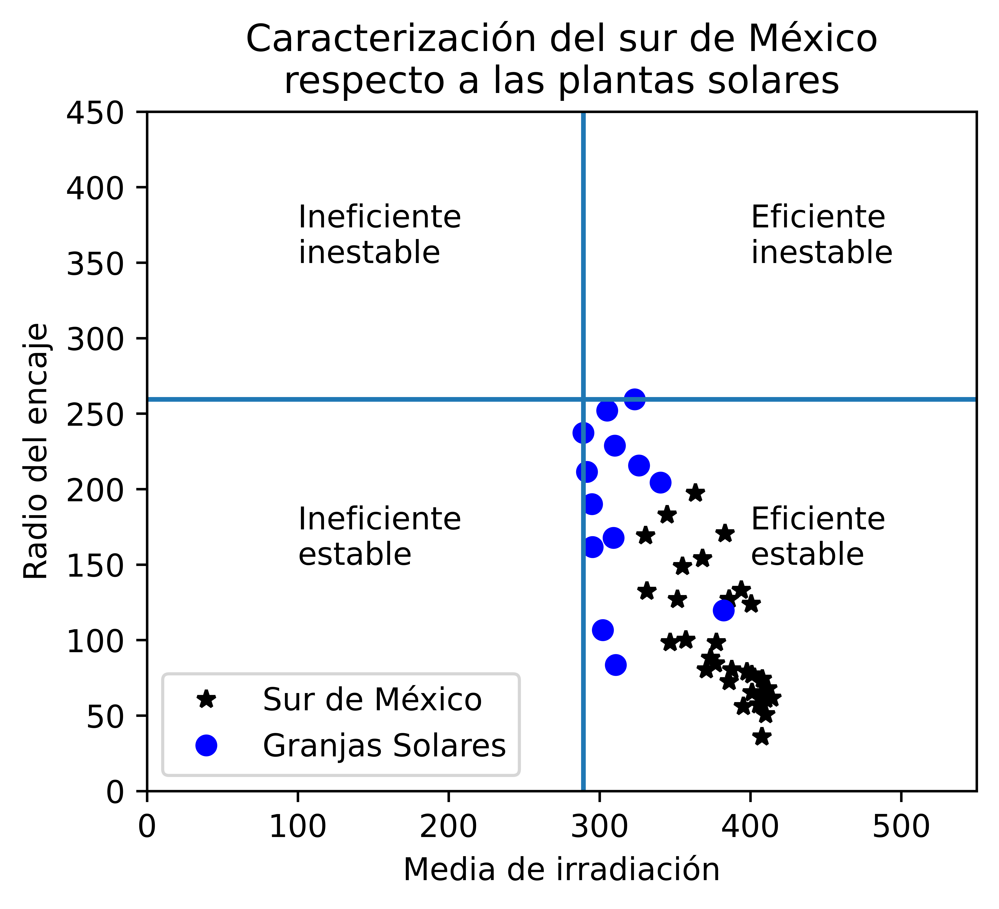

In [ ]:
plt.figure(dpi=1200)


# USA sur
for i in range(mexico_Sur.shape[0]):
  for j in range(mexico_Sur.shape[1]):
    plt.plot(mexico_Sur[i][j][0],mexico_Sur[i][j][1],'*',color='k')
plt.plot(mexico_Sur[-1][-1][0],mexico_Sur[-1][-1][1],'*',color='k',
         label='Sur de México')


## Plantas
plt.plot(mediasPlantas,radiosPlantas,'o',color='blue',label='Granjas Solares')
## Lineas
plt.axvline(x=min(mediasPlantas))
plt.axhline(y=max(radiosPlantas))
plt.xlabel('Media de irradiación')
plt.ylabel('Radio del encaje')
plt.title('Caracterización del sur de México\nrespecto a las plantas solares')


plt.annotate('Eficiente\nestable',(400,150))
plt.annotate('Eficiente \ninestable',(400,350))
plt.annotate('Ineficiente\nestable',(100,150))
plt.annotate('Ineficiente\ninestable',(100,350))

plt.xlim((0,550))
plt.ylim((0,450))


ax = plt.gca() #you first need to get the axis handle
ax.set_aspect('equal')
plt.legend(loc='lower left')


plt.show()

## Sudamérica

In [ ]:
lat_i,lon_i=np.where(SR21.lat== -4.76184)[0][0],np.where(SR21.lon== 290.625)[0][0]
lat_f,lon_f=np.where(SR21.lat== -29.5234)[0][0],np.where(SR21.lon== 309.375)[0][0]

sudamerica=np.zeros((lat_f-lat_i,lon_f-lon_i,2))

for i in range(sudamerica.shape[0]):
  for j in range(sudamerica.shape[1]):
    tmp=selector(i+lat_i,j+lon_i)
    tmp_embedded=embeddingPipelineManual(dim,delay,ma,stride,tmp,2,False)
    tmp_r=circle(tmp_embedded)
    sudamerica[i][j][0]=np.mean(tmp)
    sudamerica[i][j][1]=tmp_r

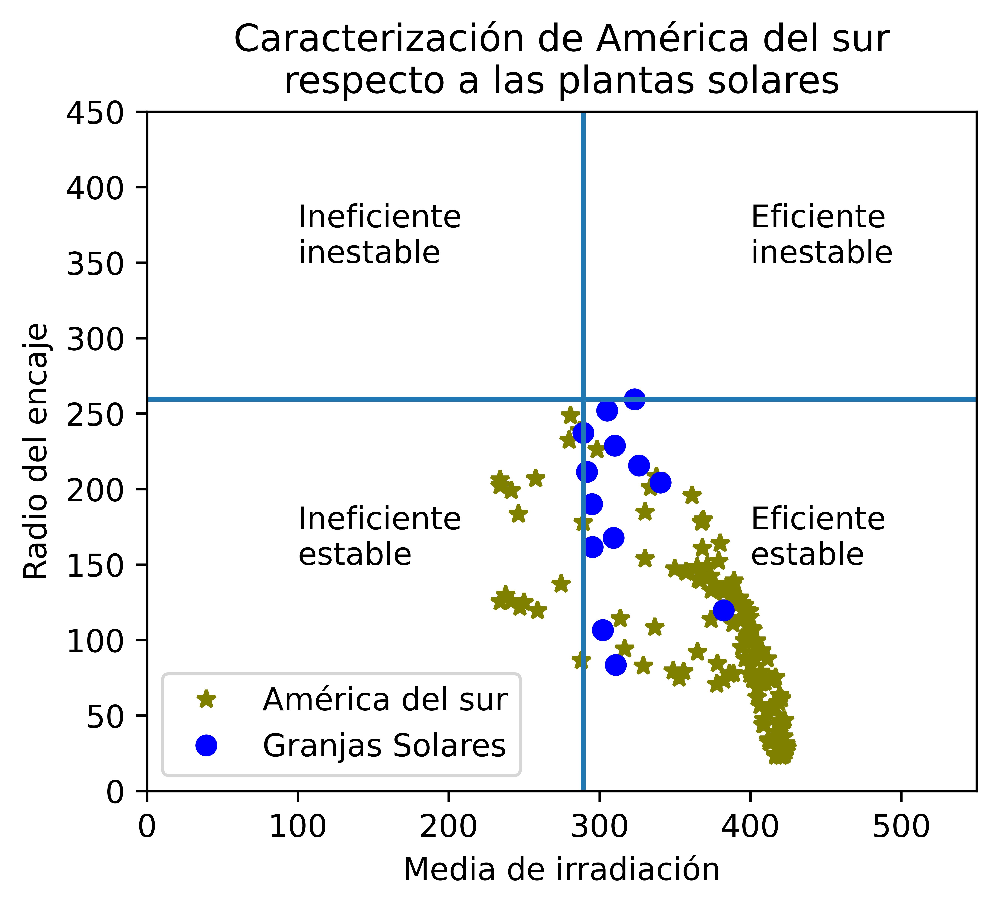

In [ ]:
plt.figure(dpi=1200)


plt.annotate('Eficiente\nestable',(400,150))
plt.annotate('Eficiente \ninestable',(400,350))
plt.annotate('Ineficiente\nestable',(100,150))
plt.annotate('Ineficiente\ninestable',(100,350))







# USA sur
for i in range(sudamerica.shape[0]):
  for j in range(sudamerica.shape[1]):
    plt.plot(sudamerica[i][j][0],sudamerica[i][j][1],'*',color='olive')
plt.plot(sudamerica[-1][-1][0],sudamerica[-1][-1][1],'*',color='olive',label='América del sur')


## Plantas
plt.plot(mediasPlantas,radiosPlantas,'o',color='blue',label='Granjas Solares')
plt.axvline(x=min(mediasPlantas))
plt.axhline(y=max(radiosPlantas))
plt.xlabel('Media de irradiación')
plt.ylabel('Radio del encaje')
plt.legend(loc='lower left')
plt.title('Caracterización de América del sur\nrespecto a las plantas solares')

plt.xlim((0,550))
plt.ylim((0,450))


ax = plt.gca() #you first need to get the axis handle
ax.set_aspect('equal')

plt.show()

## Antartida

In [ ]:
lat_i,lon_i=np.where(SR21.lat== -80.9473)[0][0],np.where(SR21.lon== 60)[0][0]
lat_f,lon_f=np.where(SR21.lat== -88.542)[0][0],np.where(SR21.lon== 90)[0][0]

antartida=np.zeros((lat_f-lat_i,lon_f-lon_i,2))

for i in range(antartida.shape[0]):
  for j in range(antartida.shape[1]):
    tmp=selector(i+lat_i,j+lon_i)
    tmp_embedded=embeddingPipelineManual(dim,delay,ma,stride,tmp,2,False)
    tmp_r=circle(tmp_embedded)
    antartida[i][j][0]=np.mean(tmp)
    antartida[i][j][1]=tmp_r

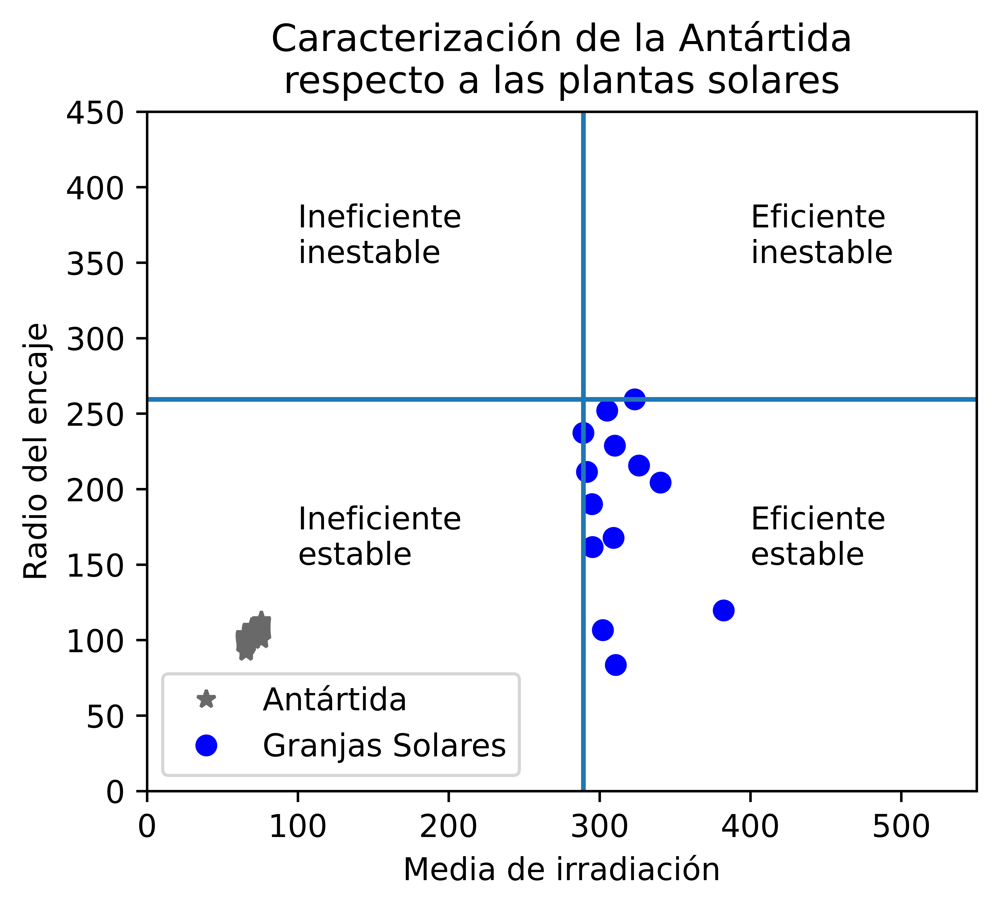

In [ ]:
plt.figure(dpi=1200)


plt.annotate('Eficiente\nestable',(400,150))
plt.annotate('Eficiente \ninestable',(400,350))
plt.annotate('Ineficiente\nestable',(100,150))
plt.annotate('Ineficiente\ninestable',(100,350))








# USA sur
for i in range(antartida.shape[0]):
  for j in range(antartida.shape[1]):
    plt.plot(antartida[i][j][0],antartida[i][j][1],'*',color='dimgrey')
plt.plot(antartida[-1][-1][0],antartida[-1][-1][1],'*',color='dimgrey',
         label='Antártida')


## Plantas
plt.plot(mediasPlantas,radiosPlantas,'o',color='blue',label='Granjas Solares')
plt.axvline(x=min(mediasPlantas))
plt.axhline(y=max(radiosPlantas))
plt.xlabel('Media de irradiación')
plt.ylabel('Radio del encaje')
plt.legend(loc='lower left')
plt.title('Caracterización de la Antártida\nrespecto a las plantas solares')


plt.xlim((0,550))
plt.ylim((0,450))


ax = plt.gca() #you first need to get the axis handle
ax.set_aspect('equal')

plt.show()

## Australia Norte

In [ ]:
lat_i,lon_i=np.where(SR21.lat== -12.3808)[0][0],np.where(SR21.lon== 120)[0][0]
lat_f,lon_f=np.where(SR21.lat== -21.9044)[0][0],np.where(SR21.lon== 144.375)[0][0]

australia_norte=np.zeros((lat_f-lat_i,lon_f-lon_i,2))

for i in range(australia_norte.shape[0]):
  for j in range(australia_norte.shape[1]):
    tmp=selector(i+lat_i,j+lon_i)
    tmp_embedded=embeddingPipelineManual(dim,delay,ma,stride,tmp,2,False)
    tmp_r=circle(tmp_embedded)
    australia_norte[i][j][0]=np.mean(tmp)
    australia_norte[i][j][1]=tmp_r

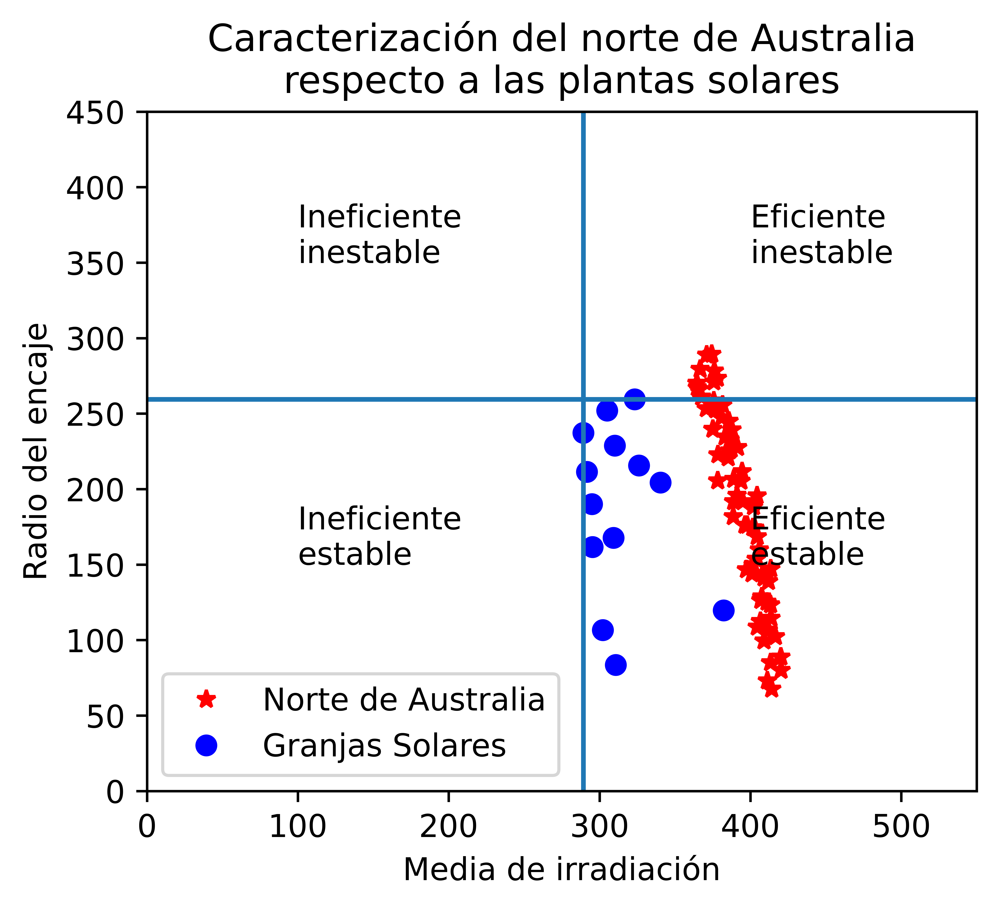

In [ ]:
plt.figure(dpi=1200)


plt.annotate('Eficiente\nestable',(400,150))
plt.annotate('Eficiente \ninestable',(400,350))
plt.annotate('Ineficiente\nestable',(100,150))
plt.annotate('Ineficiente\ninestable',(100,350))









# USA sur
for i in range(australia_norte.shape[0]):
  for j in range(australia_norte.shape[1]):
    plt.plot(australia_norte[i][j][0],australia_norte[i][j][1],'*',color='red')
plt.plot(australia_norte[-1][-1][0],australia_norte[-1][-1][1],'*',color='red',
         label='Norte de Australia')


## Plantas
plt.plot(mediasPlantas,radiosPlantas,'o',color='blue',label='Granjas Solares')
plt.axvline(x=min(mediasPlantas))
plt.axhline(y=max(radiosPlantas))
plt.xlabel('Media de irradiación')
plt.ylabel('Radio del encaje')
plt.legend(loc='lower left')
plt.title('Caracterización del norte de Australia\nrespecto a las plantas solares')


plt.xlim((0,550))
plt.ylim((0,450))


ax = plt.gca() #you first need to get the axis handle
ax.set_aspect('equal')
plt.show()

## Australia Sur

In [ ]:
lat_i,lon_i=np.where(SR21.lat== -21.9044)[0][0],np.where(SR21.lon== 120)[0][0]
lat_f,lon_f=np.where(SR21.lat== -29.5234)[0][0],np.where(SR21.lon== 144.375)[0][0]

australia_sur=np.zeros((lat_f-lat_i,lon_f-lon_i,2))

for i in range(australia_sur.shape[0]):
  for j in range(australia_sur.shape[1]):
    tmp=selector(i+lat_i,j+lon_i)
    tmp_embedded=embeddingPipelineManual(dim,delay,ma,stride,tmp,2,False)
    tmp_r=circle(tmp_embedded)
    australia_sur[i][j][0]=np.mean(tmp)
    australia_sur[i][j][1]=tmp_r

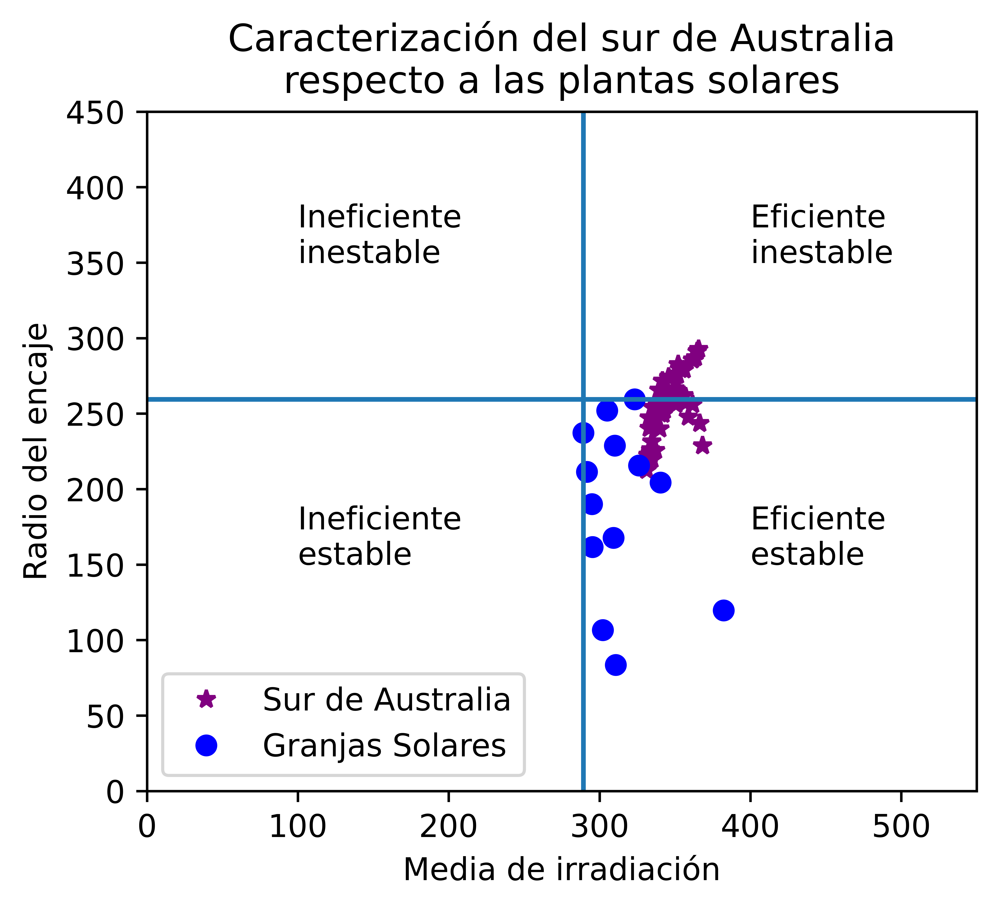

In [ ]:
plt.figure(dpi=1200)



plt.annotate('Eficiente\nestable',(400,150))
plt.annotate('Eficiente \ninestable',(400,350))
plt.annotate('Ineficiente\nestable',(100,150))
plt.annotate('Ineficiente\ninestable',(100,350))








# USA sur
for i in range(australia_sur.shape[0]):
  for j in range(australia_sur.shape[1]):
    plt.plot(australia_sur[i][j][0],australia_sur[i][j][1],'*',color='purple')
plt.plot(australia_sur[-1][-1][0],australia_sur[-1][-1][1],'*',color='purple',label='Sur de Australia')


## Plantas
plt.plot(mediasPlantas,radiosPlantas,'o',color='blue',label='Granjas Solares')
plt.axvline(x=min(mediasPlantas))
plt.axhline(y=max(radiosPlantas))
plt.xlabel('Media de irradiación')
plt.ylabel('Radio del encaje')
plt.legend(loc='lower left')
plt.title('Caracterización del sur de Australia\nrespecto a las plantas solares')
plt.xlim((0,550))
plt.ylim((0,450))


ax = plt.gca() #you first need to get the axis handle
ax.set_aspect('equal')
plt.show()

## Rusia

In [ ]:
lat_i,lon_i=np.where(SR21.lat==  69.5217)[0][0],np.where(SR21.lon== 90)[0][0]
lat_f,lon_f=np.where(SR21.lat== 50.4752)[0][0],np.where(SR21.lon== 120)[0][0]

rusia=np.zeros((lat_f-lat_i,lon_f-lon_i,2))

for i in range(rusia.shape[0]):
  for j in range(rusia.shape[1]):
    tmp=selector(i+lat_i,j+lon_i)
    tmp_embedded=embeddingPipelineManual(dim,delay,ma,stride,tmp,2,False)
    tmp_r=circle(tmp_embedded)
    rusia[i][j][0]=np.mean(tmp)
    rusia[i][j][1]=tmp_r

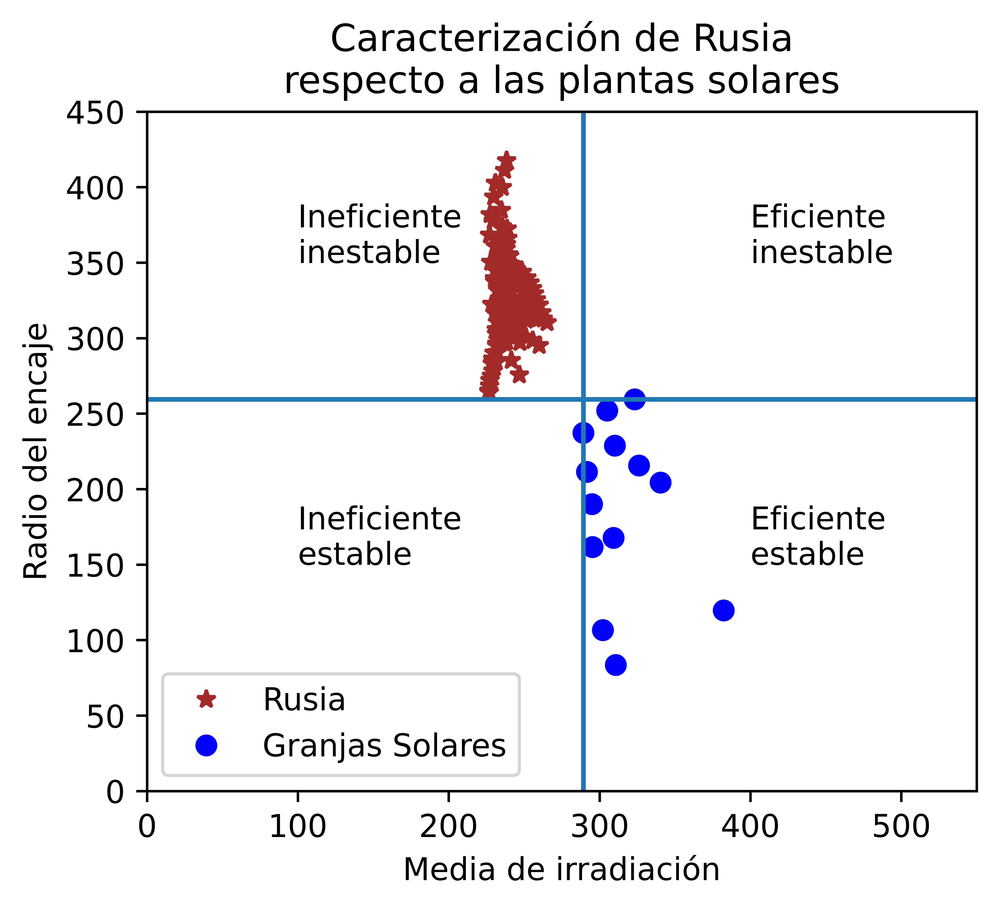

In [ ]:
plt.figure(dpi=1200)



plt.annotate('Eficiente\nestable',(400,150))
plt.annotate('Eficiente \ninestable',(400,350))
plt.annotate('Ineficiente\nestable',(100,150))
plt.annotate('Ineficiente\ninestable',(100,350))









# USA sur
for i in range(rusia.shape[0]):
  for j in range(rusia.shape[1]):
    plt.plot(rusia[i][j][0],rusia[i][j][1],'*',color='brown')
plt.plot(rusia[-1][-1][0],rusia[-1][-1][1],'*',color='brown',label='Rusia')


## Plantas
plt.plot(mediasPlantas,radiosPlantas,'o',color='blue',label='Granjas Solares')
plt.axvline(x=min(mediasPlantas))
plt.axhline(y=max(radiosPlantas))
plt.xlabel('Media de irradiación')
plt.ylabel('Radio del encaje')
plt.legend(loc='lower left')
plt.title('Caracterización de Rusia\nrespecto a las plantas solares')
plt.xlim((0,550))
plt.ylim((0,450))


ax = plt.gca() #you first need to get the axis handle
ax.set_aspect('equal')
plt.show()

## Africa central

In [ ]:
lat_i,lon_i=np.where(SR21.lat== 18.095 )[0][0],np.where(SR21.lon== 18.75)[0][0]
lat_f,lon_f=np.where(SR21.lat== -10.47604 )[0][0],np.where(SR21.lon== 35.625)[0][0]

africa_central=np.zeros((lat_f-lat_i,lon_f-lon_i,2))

for i in range(africa_central.shape[0]):
  for j in range(africa_central.shape[1]):
    tmp=selector(i+lat_i,j+lon_i)
    tmp_embedded=embeddingPipelineManual(dim,delay,ma,stride,tmp,2,False)
    tmp_r=circle(tmp_embedded)
    africa_central[i][j][0]=np.mean(tmp)
    africa_central[i][j][1]=tmp_r

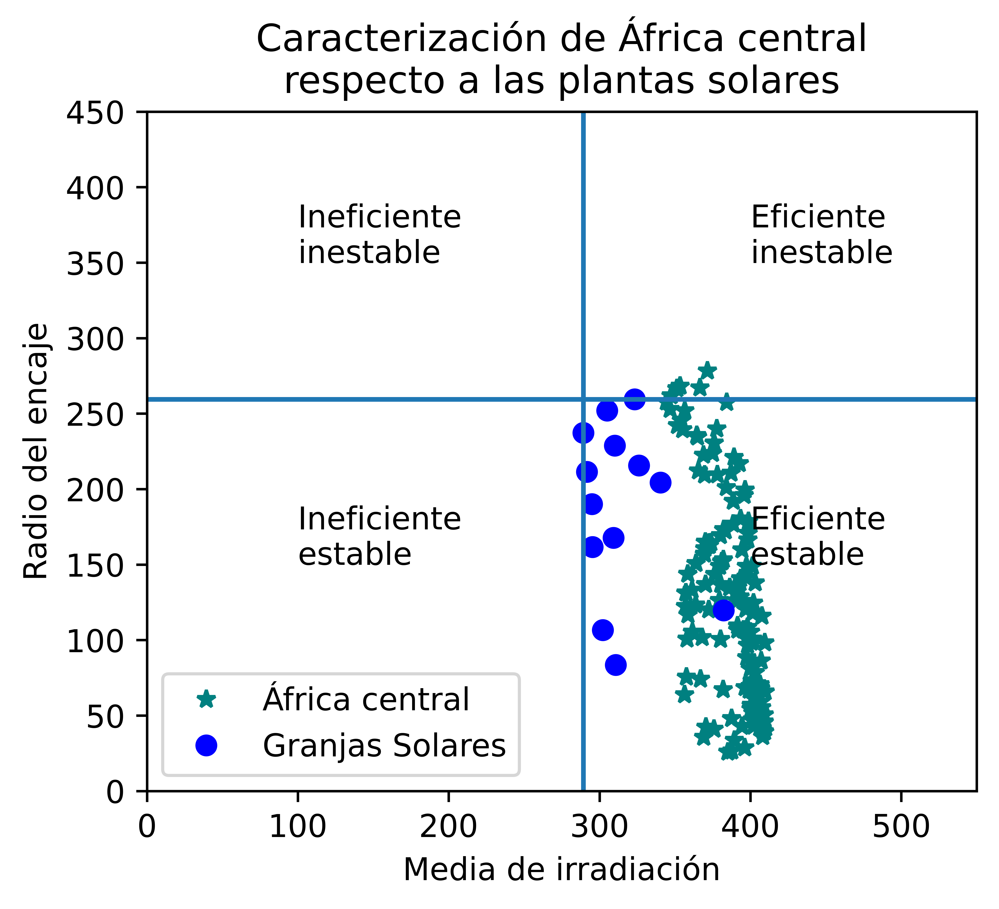

In [ ]:
plt.figure(dpi=1200)



plt.annotate('Eficiente\nestable',(400,150))
plt.annotate('Eficiente \ninestable',(400,350))
plt.annotate('Ineficiente\nestable',(100,150))
plt.annotate('Ineficiente\ninestable',(100,350))










# USA sur
for i in range(africa_central.shape[0]):
  for j in range(africa_central.shape[1]):
    plt.plot(africa_central[i][j][0],africa_central[i][j][1],'*',color='teal')
plt.plot(africa_central[-1][-1][0],africa_central[-1][-1][1],'*',color='teal',
         label='África central')


## Plantas
plt.plot(mediasPlantas,radiosPlantas,'o',color='blue',label='Granjas Solares')
plt.axvline(x=min(mediasPlantas))
plt.axhline(y=max(radiosPlantas))
plt.xlabel('Media de irradiación')
plt.ylabel('Radio del encaje')
plt.legend(loc='lower left')
plt.title('Caracterización de África central\nrespecto a las plantas solares')
plt.xlim((0,550))
plt.ylim((0,450))


ax = plt.gca() #you first need to get the axis handle
ax.set_aspect('equal')
plt.show()

# Resultados

In [ ]:
(SR21.dlwrf.time.shape,SR20.dlwrf.time.shape,SR19.dlwrf.time.shape,SR18.dlwrf.time.shape,SR17.dlwrf.time.shape)

((365,), (366,), (365,), (365,), (365,))

In [ ]:
sum(SR21.dlwrf.time.shape[0]+SR20.dlwrf.time.shape[0]+SR19.dlwrf.time.shape[0]+SR18.dlwrf.time.shape[0]+SR17.dlwrf.time.shape[0])

1826

In [ ]:
!lscpu

Architecture:        x86_64
CPU op-mode(s):      32-bit, 64-bit
Byte Order:          Little Endian
CPU(s):              2
On-line CPU(s) list: 0,1
Thread(s) per core:  2
Core(s) per socket:  1
Socket(s):           1
NUMA node(s):        1
Vendor ID:           GenuineIntel
CPU family:          6
Model:               79
Model name:          Intel(R) Xeon(R) CPU @ 2.20GHz
Stepping:            0
CPU MHz:             2200.214
BogoMIPS:            4400.42
Hypervisor vendor:   KVM
Virtualization type: full
L1d cache:           32K
L1i cache:           32K
L2 cache:            256K
L3 cache:            56320K
NUMA node0 CPU(s):   0,1
Flags:               fpu vme de pse tsc msr pae mce cx8 apic sep mtrr pge mca cmov pat pse36 clflush mmx fxsr sse sse2 ss ht syscall nx pdpe1gb rdtscp lm constant_tsc rep_good nopl xtopology nonstop_tsc cpuid tsc_known_freq pni pclmulqdq ssse3 fma cx16 pcid sse4_1 sse4_2 x2apic movbe popcnt aes xsave avx f16c rdrand hypervisor lahf_lm abm 3dnowprefetch invpcid_sin

# alch queria jugar una partida de ajedrez cuatridimensional

In [ ]:
currmax=0
currmaxy=0
j=0
z=0
for i in (US_north,US_south,mexico_Norte,mexico_Sur,sudamerica,antartida,
                australia_norte,australia_sur,rusia,africa_central):
  tmp=i.T
  if np.amax(tmp[0])>currmax:
    currmax=np.amax(tmp[0])
    j+=1
  if np.amax(tmp[1])>currmaxy:
    currmaxy=np.amax(tmp[1])
    z+=1

In [ ]:
currmax

424.25482177734375

In [ ]:
currmaxy

417.62257821173574

In [ ]:
lista=[]
for i in encajesPlantas:
  lista.append(circle(i))
yes=np.array(lista)
print(np.where(yes==np.min(yes)))
print(np.where(yes==np.max(yes)))

(array([12]),)
(array([7]),)


In [ ]:
lista[12]

83.48115069267766

In [ ]:
lista[7]

259.5193364976687

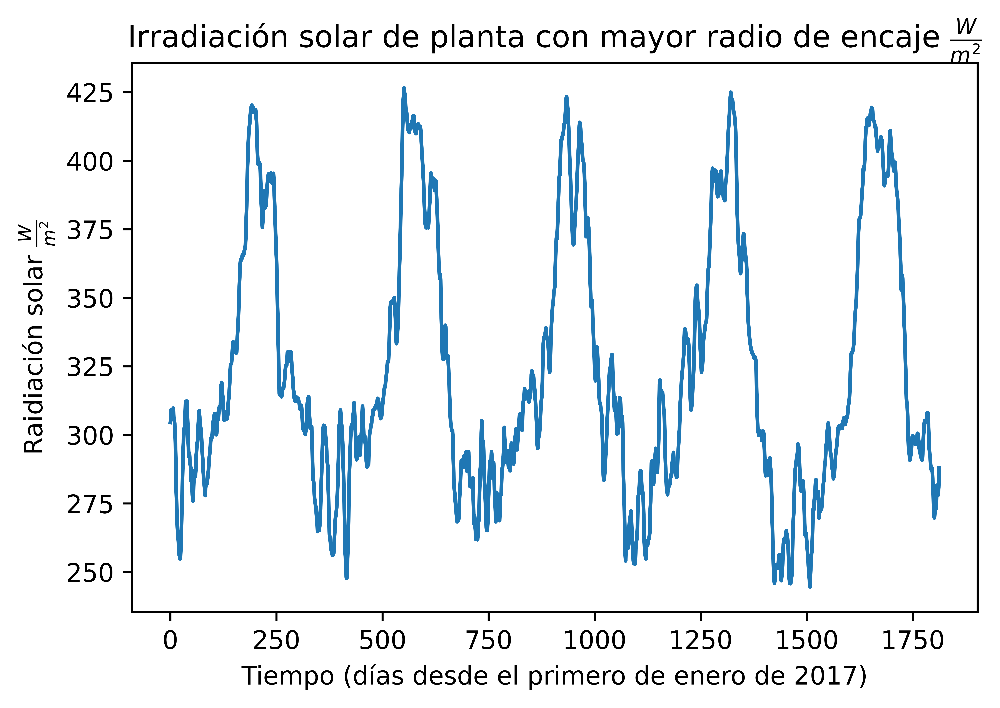

In [ ]:
plt.figure(dpi=1200)
ax = plt.gca() #you first need to get the axis handle
plt.plot(moving_average(plantas[7],14))
ax.set_xlabel('Tiempo (días desde el primero de enero de 2017)')
ax.set_ylabel(r'Raidiación solar $\frac{W}{m^2}$')
ax.set_title(r'Irradiación solar de planta con mayor radio de encaje $\frac{W}{m^2}$')
plt.show()

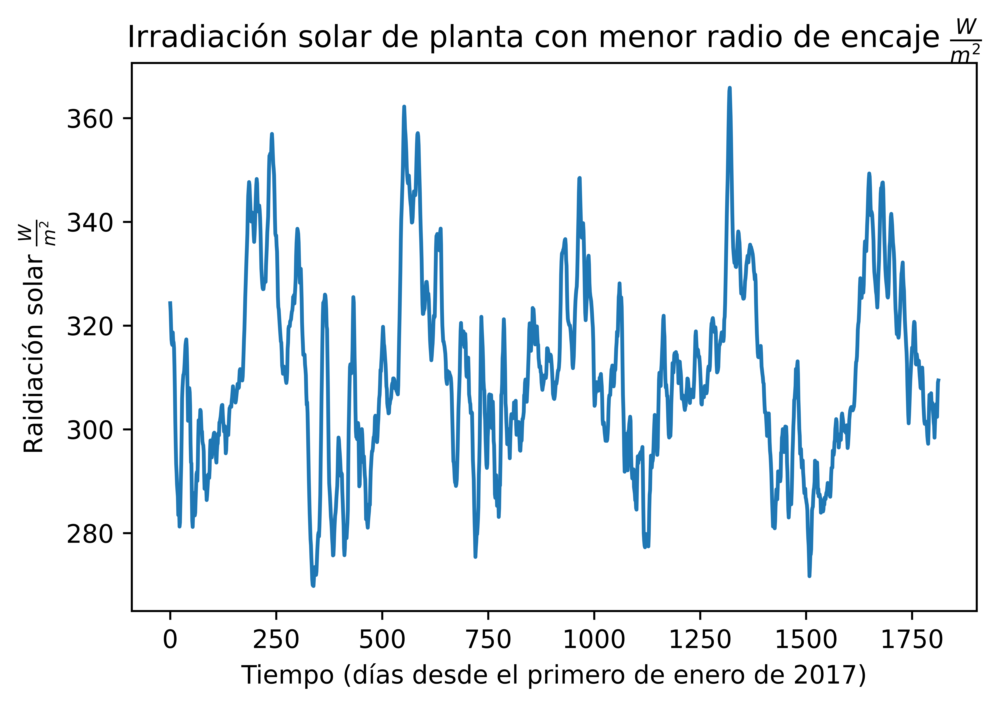

In [ ]:
plt.figure(dpi=1200)
ax = plt.gca() #you first need to get the axis handle
plt.plot(moving_average(plantas[12],14))
ax.set_xlabel('Tiempo (días desde el primero de enero de 2017)')
ax.set_ylabel(r'Raidiación solar $\frac{W}{m^2}$')
ax.set_title(r'Irradiación solar de planta con menor radio de encaje $\frac{W}{m^2}$')
plt.show()

In [ ]:
antartida.shape

(4, 16, 2)

In [ ]:
antartida.T.shape

(2, 16, 4)

### Comparacion de encajes obtenidos

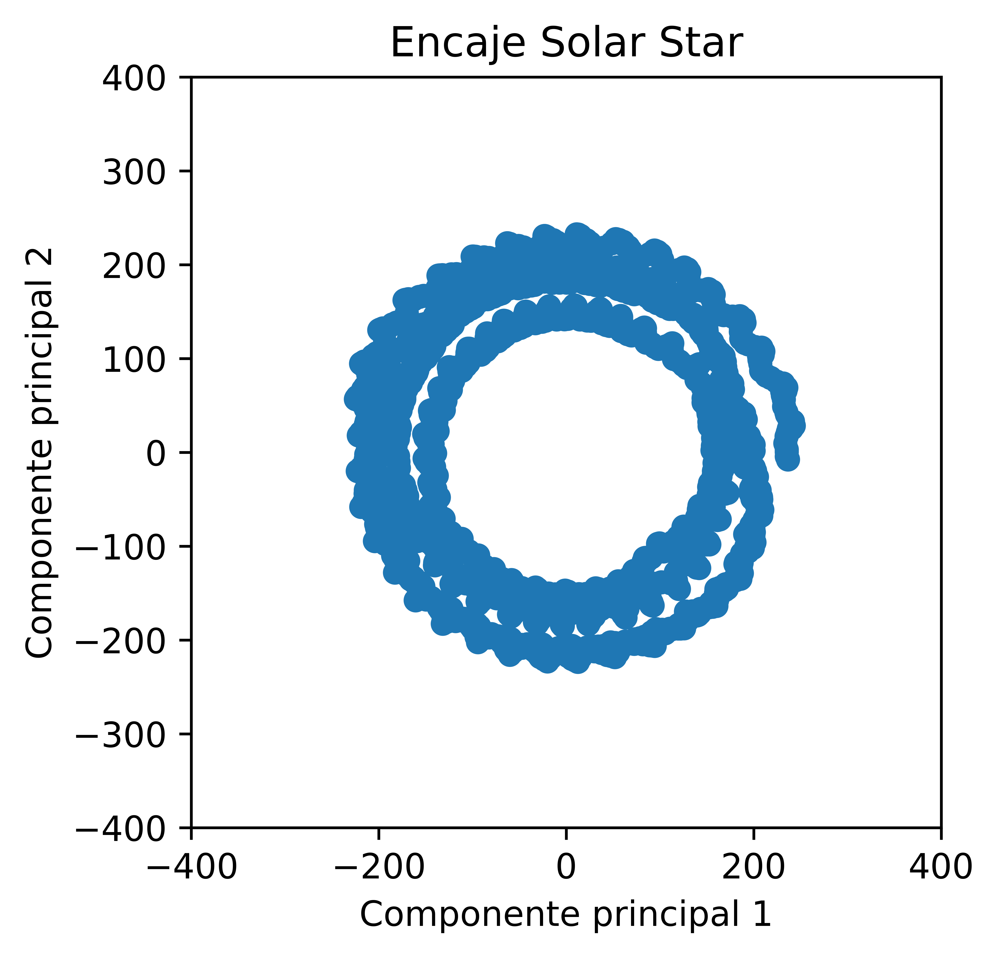

'plantas=(Benban,Solar_star,Sunlight_solar,Topaz,Mount,Mezquite,McCoy,\nAguaCaliente,Springbook,SilverState,CaliforniaValley,Westlands,Garland,\nTranquility,Cestas)\n'

In [ ]:
plt.figure(dpi=1200)

plt.scatter(encajesPlantas[1][:,0],encajesPlantas[1][:,1])
ax = plt.gca() #you first need to get the axis handle
ax.set_aspect('equal')
ax.set_title('Encaje Solar Star')
ax.set_xlabel('Componente principal 1')
ax.set_ylabel('Componente principal 2')
ax.set_xlim((-400,400))
ax.set_ylim((-400,400))
plt.show()
'''plantas=(Benban,Solar_star,Sunlight_solar,Topaz,Mount,Mezquite,McCoy,
AguaCaliente,Springbook,SilverState,CaliforniaValley,Westlands,Garland,
Tranquility,Cestas)
'''

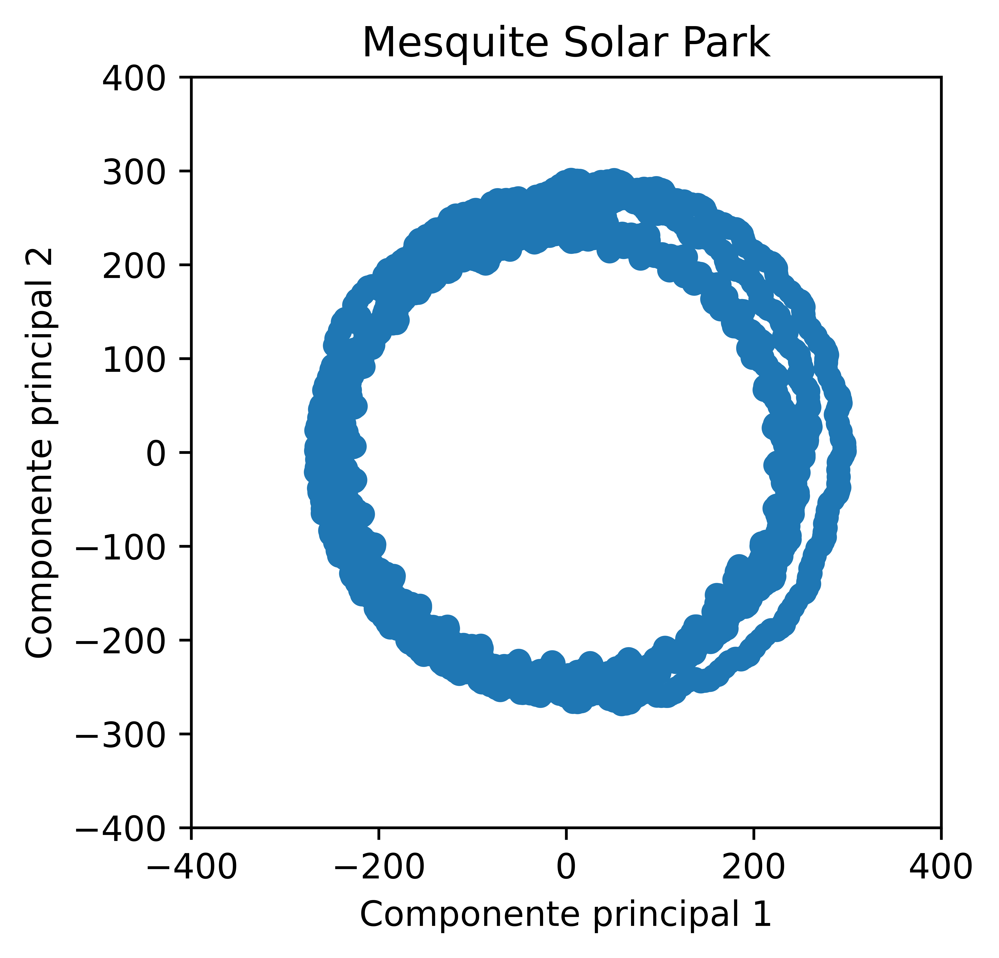

In [ ]:
plt.figure(dpi=1200)

plt.scatter(encajesPlantas[5][:,0],encajesPlantas[5][:,1])
ax = plt.gca() #you first need to get the axis handle
ax.set_aspect('equal')
ax.set_title('Mesquite Solar Park')
ax.set_xlabel('Componente principal 1')
ax.set_ylabel('Componente principal 2')
ax.set_xlim((-400,400))
ax.set_ylim((-400,400))
plt.show()

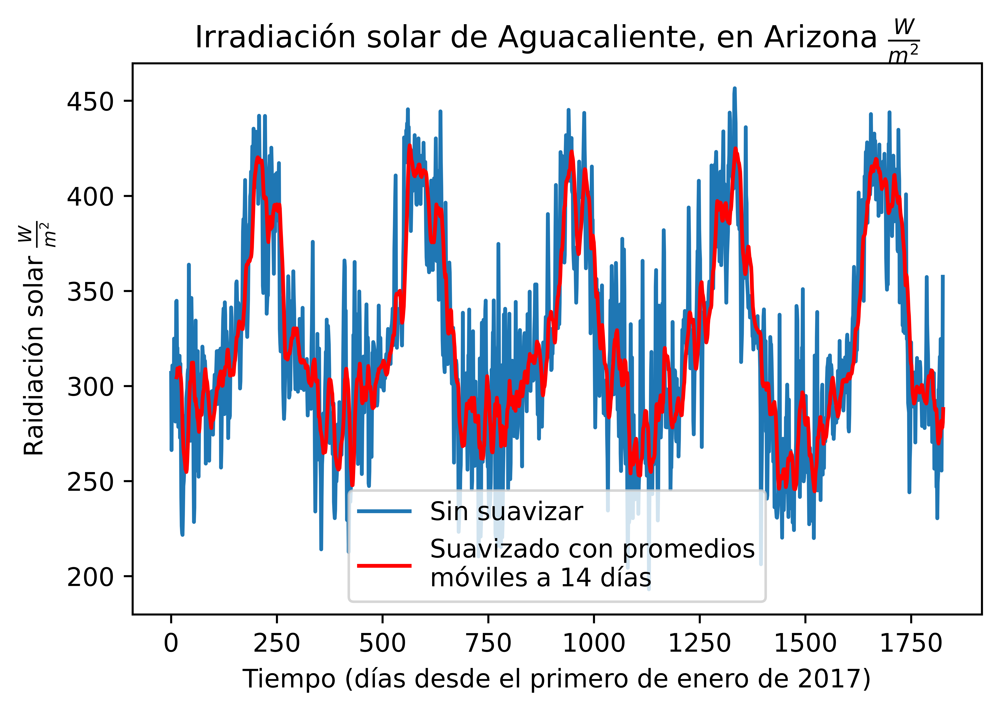

In [ ]:
plt.figure(dpi=1200)

plt.plot(AguaCaliente,label='Sin suavizar')
soft_x=np.linspace(13,len(AguaCaliente),len(AguaCaliente)-13)
plt.plot(soft_x,moving_average(AguaCaliente,14),'r',label='Suavizado con promedios\nmóviles a 14 días')

ax = plt.gca() #you first need to get the axis handle
ax.set_xlabel('Tiempo (días desde el primero de enero de 2017)')
ax.set_ylabel(r'Raidiación solar $\frac{W}{m^2}$')
ax.set_title(r'Irradiación solar de Aguacaliente, en Arizona $\frac{W}{m^2}$')
ax.legend()
plt.show()

### Por que se descartaron diagramas de persistencia

In [ ]:
# Primeros 2 años de encajes
test=[encajesPlantas[0][:720],encajesPlantas[1][:720]]

In [ ]:


# Track connected components, loops, and voids
homology_dimensions = [0, 1, 2]

# Collapse edges to speed up H2 persistence calculation!
persistence = VietorisRipsPersistence(
    metric="euclidean",
    homology_dimensions=homology_dimensions,
    n_jobs=-1)
diagrams_basic = persistence.fit_transform(test)

In [ ]:
# Diagrama de persistencia Benban
plot_diagram(diagrams_basic[0])


In [ ]:
# Diagrama de persistencia Solar Star
plot_diagram(diagrams_basic[1])